# 26.04 Act 1: Survival analysis of customer churn, Online Retail II
Question: how long does a newly acquired customer stay active, and what in their first 30 days is associated with leaving sooner?
Online Retail II is a transaction log with no churn column, so three things are built and defended here: who counts as a customer, what counts as churn, and which covariates are legal.
Out of scope: CLV, BG/NBD, Gamma-Gamma (Act 2).

In [1]:
import zipfile, os, re
import numpy as np, pandas as pd
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import proportional_hazard_test
%matplotlib inline

np.random.seed(42)
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")   # run from the repo root so data/ and outputs/ resolve
os.makedirs("outputs", exist_ok=True)
T_END = pd.Timestamp("2011-12-09")        # last date in the file, all censoring hangs on this
NEW_CUSTOMER_CUTOFF = pd.Timestamp("2010-06-01")  # modeling choice, see step 6
COV_WINDOW = 30                            # days after first order used for covariates
LOG = {}                                   # row counts collected for DATA.md

## Step 1. Load both sheets, drop rows with no Customer ID

In [2]:
PKL = "data/retail_raw.pkl"
if os.path.exists(PKL):
    raw = pd.read_pickle(PKL)
else:
    with zipfile.ZipFile("data/online_retail_II.zip") as z:
        xl = [n for n in z.namelist() if n.endswith(".xlsx")][0]
        z.extract(xl, "data")
    sheets = pd.read_excel(os.path.join("data", xl), sheet_name=None)
    print("sheets:", {k: len(v) for k, v in sheets.items()})
    raw = pd.concat(sheets.values(), ignore_index=True)
    raw.to_pickle(PKL)
print("rows:", len(raw))
print(raw.dtypes)
print("date range:", raw["InvoiceDate"].min(), "to", raw["InvoiceDate"].max())
LOG["raw_rows"] = len(raw)

rows: 1067371
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object
date range: 2009-12-01 07:45:00 to 2011-12-09 12:50:00


In [3]:
raw["Revenue"] = raw["Quantity"] * raw["Price"]
no_id = raw["Customer ID"].isna()
print(f"no Customer ID: {no_id.sum():,} rows ({no_id.mean():.1%}); share of gross revenue {raw.loc[no_id,'Revenue'].sum()/raw['Revenue'].sum():.1%}")
LOG["no_customer_id_rows"] = int(no_id.sum())
LOG["no_customer_id_revenue_share"] = float(raw.loc[no_id,'Revenue'].sum()/raw['Revenue'].sum())
df = raw.loc[~no_id].copy()
df["Customer ID"] = df["Customer ID"].astype(int)
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)
print("rows with Customer ID:", len(df))

no Customer ID: 243,007 rows (22.8%); share of gross revenue 13.7%


rows with Customer ID: 824364


## Step 2. Cleaning
Each rule is counted on the rows still remaining when it is applied, so the counts add up. Nothing else is dropped.

In [4]:
NON_PRODUCT = {"POST","D","M","C2","BANK CHARGES","ADJUST","ADJUST2","S","AMAZONFEE","DOT","CRUK","TEST001","TEST002","PADS","B"}
rules = [
    ("cancellation invoice (Invoice starts with C)", df["Invoice"].str.startswith("C")),
    ("Quantity <= 0", df["Quantity"] <= 0),
    ("Price <= 0", df["Price"] <= 0),
    ("non-product StockCode", df["StockCode"].str.upper().isin(NON_PRODUCT)),
]
clean = df
LOG["rules"] = []
for name, _ in rules:
    pass
cur = df
for name, _ in rules:
    # re-evaluate on the current frame so counts are sequential
    if name.startswith("cancellation"): m = cur["Invoice"].str.startswith("C")
    elif name.startswith("Quantity"):   m = cur["Quantity"] <= 0
    elif name.startswith("Price"):      m = cur["Price"] <= 0
    else:                               m = cur["StockCode"].str.upper().isin(NON_PRODUCT)
    print(f"{name}: removed {m.sum():,}")
    LOG["rules"].append((name, int(m.sum())))
    cur = cur.loc[~m]
removed_codes = df.loc[df["StockCode"].str.upper().isin(NON_PRODUCT), "StockCode"].value_counts()
print("\nnon-product codes removed (before other rules):"); print(removed_codes.to_string())
df = cur.copy()
LOG["clean_rows"] = len(df)
print("\nrows after cleaning:", len(df))
odd = df.loc[~df["StockCode"].str.match(r"^\d{5}"), "StockCode"].value_counts().head(15)
print("\nremaining StockCodes not starting with 5 digits (kept, top 15, for visibility):"); print(odd.to_string())

cancellation invoice (Invoice starts with C): removed 18,744
Quantity <= 0: removed 0
Price <= 0: removed 71


non-product StockCode: removed 2,915



non-product codes removed (before other rules):
StockCode
POST            2019
M               1115
C2               259
D                174
ADJUST            61
BANK CHARGES      38
PADS              19
DOT               16
CRUK              16
TEST001           15
ADJUST2            3
TEST002            1

rows after cleaning: 802634



remaining StockCodes not starting with 5 digits (kept, top 15, for visibility):
StockCode
SP1002    2


## Step 3. One row per order, customer table
An order is one Invoice. Order date is the calendar date of the invoice.

In [5]:
df["Date"] = df["InvoiceDate"].dt.normalize()
df["Revenue"] = df["Quantity"] * df["Price"]
orders = (df.groupby(["Customer ID", "Invoice"])
            .agg(Date=("Date", "min"), Value=("Revenue", "sum"), Items=("Quantity", "sum"), Country=("Country", "first"))
            .reset_index())
cust = (orders.groupby("Customer ID")
              .agg(first=("Date", "min"), last=("Date", "max"), n_orders=("Invoice", "nunique"))
              .reset_index())
print("orders:", len(orders), " customers:", len(cust))
print(cust["n_orders"].describe())
LOG["orders"] = len(orders); LOG["customers_all"] = len(cust)

orders: 36594  customers: 5852
count    5852.000000
mean        6.253247
std        12.749286
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       373.000000
Name: n_orders, dtype: float64


## Step 4. Gaps between consecutive orders
Gaps are measured between consecutive distinct order days, so two invoices on the same day are one visit and do not produce a gap of zero. Only customers with 2 or more order days contribute.

customers with 2+ order days: 4,179;  gaps: 27,026
{75: 70.0, 90: 148.0, 95: 221.0}


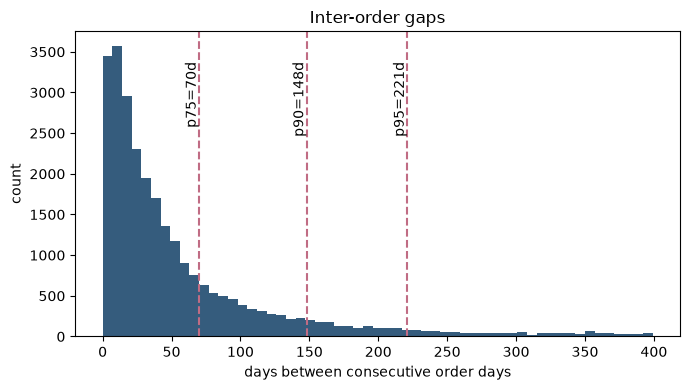

In [6]:
days = orders[["Customer ID", "Date"]].drop_duplicates().sort_values(["Customer ID", "Date"])
days["gap"] = days.groupby("Customer ID")["Date"].diff().dt.days
gaps = days["gap"].dropna()
P = {q: float(np.percentile(gaps, q)) for q in (75, 90, 95)}
print(f"customers with 2+ order days: {days.groupby('Customer ID').size().ge(2).sum():,};  gaps: {len(gaps):,}")
print({q: round(v, 1) for q, v in P.items()})
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(gaps, bins=np.arange(0, 400, 7), color="#355c7d")
for q, v in P.items():
    ax.axvline(v, color="#c06c84", ls="--"); ax.text(v, ax.get_ylim()[1]*0.9, f"p{q}={v:.0f}d", rotation=90, va="top", ha="right")
ax.set_xlabel("days between consecutive order days"); ax.set_ylabel("count"); ax.set_title("Inter-order gaps")
fig.tight_layout(); fig.savefig("outputs/01_gap_distribution.png", dpi=150); plt.show()
LOG["gap_pcts"] = P

## Step 5. Churn definition
N is the inactivity window. A customer has churned if there are N days with no order after their last order and that window closed on or before T_end. Otherwise they are censored: we do not know yet.
N starts at the 90th percentile gap, rounded to whole days. Reason: it is the gap that all but the slowest 10 percent of returning customers beat, so silence longer than this is unusual for the customer base. It is a choice, not a fact: step 11 shows how much the answer moves with it.

In [7]:
N = int(round(P[90]))   # modeling choice, one cell

def build_surv(cust, N):
    c = cust.copy()
    c["churned"] = (c["last"] + pd.to_timedelta(N, unit="D")) <= T_END
    c["event"] = c["churned"].astype(int)
    c["duration"] = np.where(c["churned"],
                             (c["last"] - c["first"]).dt.days + N,
                             (T_END - c["first"]).dt.days)
    return c

surv = build_surv(cust, N)
print("N =", N)
print("churned:", surv["event"].sum(), " censored:", (1 - surv["event"]).sum(), f" censored share {1-surv['event'].mean():.1%}")

N = 148
churned: 2581  censored: 3271  censored share 55.9%


## Step 6. Left-truncation guard
The file starts on 2009-12-01, so a customer whose first order is in the first stretch of the file may be an existing customer, not a new one. We keep only customers whose first order is on or after 2010-06-01 (a choice, about 6 months of look-back, and longer than the 90th percentile gap).
A second guard, needed for the covariates in step 8: a customer needs a full 30-day window observed before T_end, otherwise their first-30-day covariates are computed from an incomplete window.

In [8]:
def apply_guards(s):
    a = s[s["first"] >= NEW_CUSTOMER_CUTOFF]
    b = a[(T_END - a["first"]).dt.days >= COV_WINDOW]
    return a, b
a, b = apply_guards(surv)
print("customers before guards:", len(surv))
print("removed by first-order cutoff 2010-06-01:", len(surv) - len(a))
print("removed because first 30 days not fully observed:", len(a) - len(b))
print("customers kept:", len(b))
LOG["guard_cutoff_removed"] = len(surv) - len(a); LOG["guard_window_removed"] = len(a) - len(b); LOG["customers_kept"] = len(b)
model = b.copy()

customers before guards: 5852
removed by first-order cutoff 2010-06-01: 2684
removed because first 30 days not fully observed: 152
customers kept: 3016


## Step 7. Kaplan-Meier

median survival time (days): 307.0
share censored: 0.562
             N=148
timeline          
554.0     0.324879
555.0     0.324879
556.0     0.324879


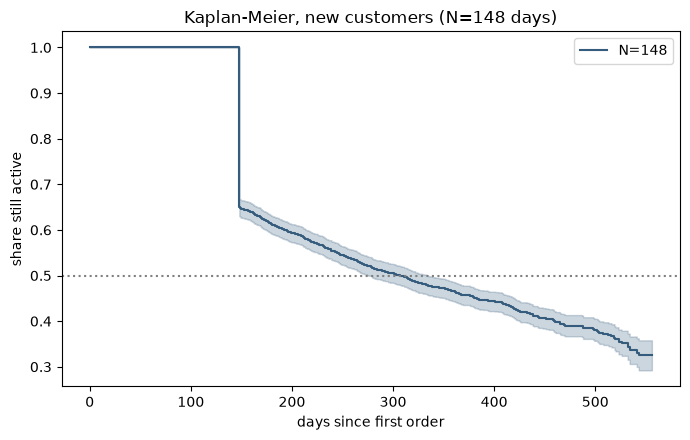

In [9]:
kmf = KaplanMeierFitter()
kmf.fit(model["duration"], model["event"], label=f"N={N}")
print("median survival time (days):", kmf.median_survival_time_)
print("share censored:", round(1 - model["event"].mean(), 3))
print(kmf.survival_function_.tail(3))
fig, ax = plt.subplots(figsize=(7, 4.5))
kmf.plot_survival_function(ax=ax, color="#355c7d")
ax.axhline(0.5, color="grey", ls=":"); ax.set_xlabel("days since first order"); ax.set_ylabel("share still active")
ax.set_title(f"Kaplan-Meier, new customers (N={N} days)")
fig.tight_layout(); fig.savefig("outputs/02_km_overall.png", dpi=150); plt.show()

## Step 8. Covariates from the first 30 days only
Measured on orders dated within 30 days of the customer's first order, nothing later. Four covariates: log first-order value, items in the first order (log1p, heavy tailed), number of orders in the first 30 days, UK or not.
Single-order customers: by construction they have one order and then silence. If the window closed they are churned with duration N (they never came back within N days); if not they are censored. They stay in the model as the "did not return" group, which is the most common outcome in this kind of data, and their first-30-day order count is 1.

In [10]:
o = orders.merge(model[["Customer ID", "first"]], on="Customer ID")
o["d"] = (o["Date"] - o["first"]).dt.days
first_order = (o.sort_values(["Customer ID", "Date", "Invoice"]).groupby("Customer ID").first())
w = o[o["d"] <= COV_WINDOW].groupby("Customer ID").agg(orders_30d=("Invoice", "nunique"))
cov = pd.DataFrame({
    "log_first_value": np.log(first_order["Value"]),
    "log_first_items": np.log1p(first_order["Items"]),
    "uk": (first_order["Country"] == "United Kingdom").astype(int),
}).join(w)
X = model.set_index("Customer ID")[["duration", "event"]].join(cov)
print(X.describe().T[["mean", "std", "min", "max"]])
print("single-order customers:", int((model.set_index('Customer ID')['n_orders'] == 1).sum()), "of", len(X))
print("share UK:", round(X["uk"].mean(), 3))

                       mean         std        min         max
duration         234.665451  145.452221  30.000000  556.000000
event              0.438329    0.496264   0.000000    1.000000
log_first_value    5.620325    0.854070   1.064711   10.409335
log_first_items    5.013234    1.050250   0.693147   11.375593
uk                 0.895889    0.305456   0.000000    1.000000
orders_30d         1.304377    0.696493   1.000000    8.000000
single-order customers: 1119 of 3016
share UK: 0.896


## Step 9. Cox proportional hazards
The three numeric covariates are standardised (z-score), so a hazard ratio is per one standard deviation. UK is a 0/1 flag and stays unstandardised.

<lifelines.CoxPHFitter: fitted with 3016 total observations, 1694 right-censored observations>
             duration col = 'duration'
                event col = 'event'
      baseline estimation = breslow
   number of observations = 3016
number of events observed = 1322
   partial log-likelihood = -9568.094
         time fit was run = 2026-10-01 04:39:54 UTC

---
                  coef exp(coef)  se(coef)  coef lower 95%  coef upper 95% exp(coef) lower 95% exp(coef) upper 95%
covariate                                                                                                         
log_first_value -0.161     0.851     0.052          -0.263          -0.059               0.768               0.943
log_first_items -0.065     0.937     0.051          -0.166           0.035               0.847               1.035
uk               0.050     1.051     0.097          -0.139           0.239               0.870               1.270
orders_30d      -0.275     0.759     0.037          -0.349          -0.202               0.706               0.817

                 cmp to      z       p  -log2(p)
covariate                                       
log_first_value   0.000 -3.087   0.002     8.952
log_first_items   0.000 -1.281   0.200     2.321
uk                0.000  0.518   0.604     0.727
orders_30d        0.000 -7.354 <0.0005    42.238
---
Concordance = 0.628
Partial AIC = 19144.188
log-likelihood ratio test = 142.097 on 4 df
-log2(p) of ll-ratio test = 96.330

                    HR  CI95_low  CI95_high
covariate                                  
log_first_value  0.851     0.768      0.943
log_first_items  0.937     0.847      1.035
uk               1.051     0.870      1.270
orders_30d       0.759     0.706      0.817
concordance: 0.628


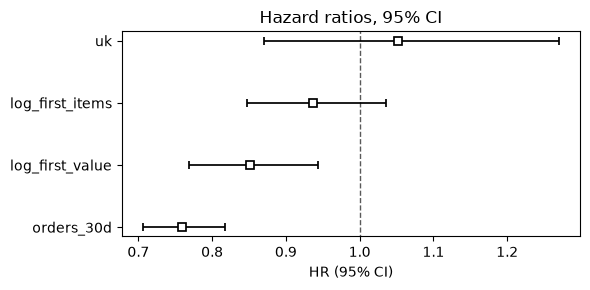

In [11]:
Z = X.copy()
for c in ["log_first_value", "log_first_items", "orders_30d"]:
    Z[c] = (Z[c] - Z[c].mean()) / Z[c].std()
Z = Z[Z["duration"] > 0]
cph = CoxPHFitter()
cph.fit(Z, duration_col="duration", event_col="event")
cph.print_summary(decimals=3)
hr = pd.DataFrame({"HR": np.exp(cph.params_), "CI95_low": np.exp(cph.confidence_intervals_.iloc[:, 0]), "CI95_high": np.exp(cph.confidence_intervals_.iloc[:, 1])})
print(hr.round(3))
print("concordance:", round(cph.concordance_index_, 3))
fig, ax = plt.subplots(figsize=(6, 3))
cph.plot(hazard_ratios=True, ax=ax); ax.set_title("Hazard ratios, 95% CI")
fig.tight_layout(); fig.savefig("outputs/03_hazard_ratios.png", dpi=150); plt.show()

## Step 10. Proportional hazards check (Schoenfeld)

In [12]:
ph = proportional_hazard_test(cph, Z, time_transform="rank")
print(ph.summary.round(4))
failed = ph.summary[ph.summary["p"] < 0.05].index.tolist()
print("covariates failing at 5%:", failed)

                 test_statistic       p  -log2(p)
log_first_items          1.1280  0.2882    1.7948
log_first_value          1.5388  0.2148    2.2189
orders_30d             104.5350  0.0000   79.0992
uk                      31.9044  0.0000   25.8799
covariates failing at 5%: ['orders_30d', 'uk']


In [13]:
# With a sample this large, small departures fail. Show the effect size with a stratified refit when UK fails.
if "uk" in failed:
    cph_s = CoxPHFitter().fit(Z, duration_col="duration", event_col="event", strata=["uk"])
    cmp = pd.DataFrame({"HR_main": np.exp(cph.params_), "HR_strat_on_uk": np.exp(cph_s.params_)}).dropna()
    print(cmp.round(3))
else:
    print("UK passes, no stratification needed")

                 HR_main  HR_strat_on_uk
covariate                               
log_first_items    0.937           0.936
log_first_value    0.851           0.852
orders_30d         0.759           0.759


## Step 11. Sensitivity to N (75th, 90th, 95th percentile gap)

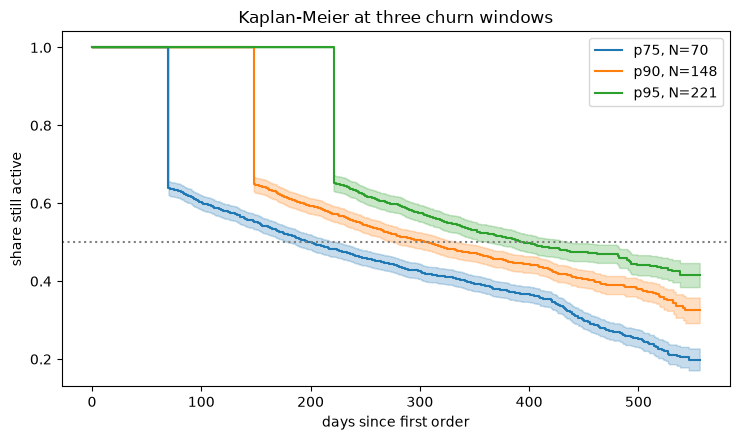

 pct   N  customers  churned_share  censored_share  median_days
  75  70       3016          0.575           0.425        201.0
  90 148       3016          0.438           0.562        307.0
  95 221       3016          0.353           0.647        395.0


In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
sens = []
for q in (75, 90, 95):
    Nq = int(round(P[q]))
    sq = build_surv(cust, Nq)
    sq = sq[(sq["first"] >= NEW_CUSTOMER_CUTOFF) & ((T_END - sq["first"]).dt.days >= COV_WINDOW)]
    k = KaplanMeierFitter().fit(sq["duration"], sq["event"], label=f"p{q}, N={Nq}")
    k.plot_survival_function(ax=ax)
    sens.append({"pct": q, "N": Nq, "customers": len(sq), "churned_share": round(sq["event"].mean(), 3),
                 "censored_share": round(1 - sq["event"].mean(), 3), "median_days": k.median_survival_time_})
ax.axhline(0.5, color="grey", ls=":"); ax.set_xlabel("days since first order"); ax.set_ylabel("share still active")
ax.set_title("Kaplan-Meier at three churn windows")
fig.tight_layout(); fig.savefig("outputs/04_km_sensitivity.png", dpi=150); plt.show()
sens = pd.DataFrame(sens); print(sens.to_string(index=False))
LOG["sens"] = sens.to_dict("records")

## Step 12. DATA.md

In [15]:
from datetime import date
lines = ["# DATA.md", "",
 "Source: UCI Machine Learning Repository, Online Retail II, https://archive.ics.uci.edu/dataset/502/online+retail+ii",
 "Licence: CC BY 4.0",
 f"Downloaded: {date.today().isoformat()}", "",
 "The raw file is not committed. Download it into data/ as online_retail_II.zip.", "",
 "## Row counts", "",
 f"- Raw rows (both sheets): {LOG['raw_rows']:,}",
 f"- No Customer ID, dropped: {LOG['no_customer_id_rows']:,} rows ({LOG['no_customer_id_rows']/LOG['raw_rows']:.1%} of rows, {LOG['no_customer_id_revenue_share']:.1%} of gross revenue)"]
for name, n in LOG["rules"]:
    lines.append(f"- {name}: {n:,} rows removed")
lines += [f"- Clean rows: {LOG['clean_rows']:,}", f"- Orders (customer x invoice): {LOG['orders']:,}", f"- Customers: {LOG['customers_all']:,}", "",
 "## Modeling choices", "",
 f"- T_end = 2011-12-09, churn window N = {N} days (90th percentile gap), sensitivity at the 75th and 95th",
 f"- New-customer cutoff: first order on or after 2010-06-01, removed {LOG['guard_cutoff_removed']:,} customers",
 f"- First 30 days must be fully observed before T_end, removed {LOG['guard_window_removed']:,} customers",
 f"- Customers modelled: {LOG['customers_kept']:,}",
 "- Gaps are measured between distinct order days"]
open("DATA.md", "w").write("\n".join(lines) + "\n")
print(open("DATA.md").read())

# DATA.md

Source: UCI Machine Learning Repository, Online Retail II, https://archive.ics.uci.edu/dataset/502/online+retail+ii
Licence: CC BY 4.0
Downloaded: 2026-10-01

The raw file is not committed. Download it into data/ as online_retail_II.zip.

## Row counts

- Raw rows (both sheets): 1,067,371
- No Customer ID, dropped: 243,007 rows (22.8% of rows, 13.7% of gross revenue)
- cancellation invoice (Invoice starts with C): 18,744 rows removed
- Quantity <= 0: 0 rows removed
- Price <= 0: 71 rows removed
- non-product StockCode: 2,915 rows removed
- Clean rows: 802,634
- Orders (customer x invoice): 36,594
- Customers: 5,852

## Modeling choices

- T_end = 2011-12-09, churn window N = 148 days (90th percentile gap), sensitivity at the 75th and 95th
- New-customer cutoff: first order on or after 2010-06-01, removed 2,684 customers
- First 30 days must be fully observed before T_end, removed 152 customers
- Customers modelled: 3,016
- Gaps are measured between distinct order days



## Limitations
1. Churn is a definition, not an observation. N is a percentile of gaps between orders, and the share churned moves from about 58 percent (N at the 75th percentile) to about 35 percent (95th) on the same customers. The median survival time moves from 201 to 395 days with it, so no single number here is the true churn rate.
2. One-and-done customers fix the shape of the curve. About a third of the modelled customers order once, are counted as churned at exactly N days, and produce the step at day N. That is a property of the duration formula, and it means the hazard ratios mostly separate returners from non-returners. In particular orders in the first 30 days is partly the outcome seen early: a second order in the window is a return.
3. Proportional hazards does not hold for orders in the first 30 days or for UK versus non-UK, so each of those hazard ratios is an average over time, not a constant effect. Stratifying on UK left the other three ratios almost unchanged, but orders_30d was only reported as a limitation. The model also discriminates modestly (concordance about 0.63), the covariates are real but weak. Wholesale buyers order in bursts and seasonally, so a long gap may be a seasonal buyer, and the file covers only two years of one retailer, so it generalises to no other business.